# Notebook 2 - Machine Learning: Training and Evaluating the Sentiment Model

**Project:** YouTube Sentiment Analyzer
**Goal:** train a classifier that predicts **Positive / Negative / Neutral** for a comment, measure how good it is honestly, and save it for the web app.

**Steps:** load data → clean → train/test split → TF-IDF → train model → evaluate → compare models → understand the model → predict new comments → save

The text-processing steps are explained in `1_NLP_Text_Processing.ipynb`.
> Run with **Kernel → Restart & Run All**. Keep this file inside the `notebooks/` folder of the project.

## 0. Setup

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR))
from ml.preprocess import clean_text

LABELS = ["Positive", "Negative", "Neutral"]
COLORS = {"Positive": "#16a34a", "Negative": "#dc2626", "Neutral": "#d97706"}
RANDOM_STATE = 42
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 90)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. The machine learning problem

- **Type:** supervised learning, **multi-class classification**
- **Input (X):** a cleaned comment (as TF-IDF numbers)
- **Output (y):** one of 3 classes - Positive, Negative, Neutral
- **Supervised** means the model learns from comments that already have the right label.

## 2. Load and clean the data

In [2]:
df = pd.read_csv(PROJECT_DIR / "data" / "training_data.csv")
df = df.dropna(subset=["text", "label"])
df["label"] = df["label"].str.strip().str.capitalize()
df = df[df["label"].isin(LABELS)]
df["clean"] = df["text"].apply(clean_text)
df = df[df["clean"].str.len() > 0].drop_duplicates(subset=["clean", "label"]).reset_index(drop=True)

print("Comments:", len(df))
print(df["label"].value_counts().to_string())
df[["text", "clean", "label"]].head(6)

Comments: 557
label
Positive    186
Neutral     186
Negative    185


,text,clean,label
0,"This is the best tutorial I have ever watched, thank you so much",best tutorial ever watched thank much,Positive
1,"Absolutely loved this video, subscribed immediately",absolutely loved video subscribed immediately,Positive
2,"Great explanation, I finally understand how this works",great explanation finally understand how works,Positive
3,"You explain things so clearly, keep up the amazing work",explain things clearly keep amazing work,Positive
4,"Wow, this blew my mind. Brilliant content",wow blew mind brilliant content,Positive
5,Thanks to this video I passed my exam today,thanks video passed exam today,Positive


## 3. Train / test split

We hide **20 %** of the data (the *test set*) and train only on the other **80 %**.
The test set simulates "new comments the model has never seen", so the final score is honest.

- `stratify=y` keeps the same class proportions in both parts
- `random_state=42` makes the split repeatable

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, random_state=RANDOM_STATE, stratify=df["label"])

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))
print("\nTrain class counts:", y_train.value_counts().to_dict())
print("Test class counts :", y_test.value_counts().to_dict())

Training samples: 445
Testing samples : 112

Train class counts: {'Positive': 149, 'Neutral': 148, 'Negative': 148}
Test class counts : {'Neutral': 38, 'Positive': 37, 'Negative': 37}


## 4. TF-IDF vectorization

Important: the vectorizer is **fitted on the training data only**, then used to *transform* the test data.
Fitting on the test set would leak information (data leakage) and make the score look better than it really is.

In [4]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)
X_train_vec = vectorizer.fit_transform(X_train)   # learn vocabulary + IDF from training data
X_test_vec = vectorizer.transform(X_test)         # only apply it to the test data

print("Training matrix:", X_train_vec.shape, "(comments x features)")
print("Testing matrix :", X_test_vec.shape)

Training matrix: (445, 2322) (comments x features)
Testing matrix : (112, 2322)


## 5. Train the model: Logistic Regression

Logistic Regression learns **one weight per feature (word / word pair) for each class**.
For a comment it adds up `weight x TF-IDF value`, then the **softmax** function converts the 3 totals into
probabilities that sum to 1. The biggest probability is the prediction, and it is the **confidence** shown in the web app.

Settings used: `C=4.0` (how closely to fit the training data; smaller = stronger regularisation) and `class_weight="balanced"`.

In [5]:
model = LogisticRegression(C=4.0, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
model.fit(X_train_vec, y_train)
print("Trained. Classes learned:", list(model.classes_))
print("Weight matrix shape (classes x features):", model.coef_.shape)

Trained. Classes learned: ['Negative', 'Neutral', 'Positive']
Weight matrix shape (classes x features): (3, 2322)


## 6. Evaluate on the unseen test set

### Metrics explained
- **Accuracy** = correct predictions / all predictions
- **Precision** (for a class) = of the comments predicted as that class, how many really are?  `TP / (TP + FP)`
- **Recall** (for a class) = of the comments that really are that class, how many did we find?  `TP / (TP + FN)`
- **F1 score** = harmonic mean of precision and recall: `2PR / (P + R)`
- **Macro average** = simple average over the 3 classes

In [6]:
y_pred = model.predict(X_test_vec)

accuracy = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, labels=LABELS, average="macro", zero_division=0)

summary = pd.DataFrame({"Metric": ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 score (macro)"],
                        "Value": [accuracy, p, r, f1]})
summary["Value"] = (summary["Value"] * 100).round(2).astype(str) + " %"
summary

,Metric,Value
0,Accuracy,87.5 %
1,Precision (macro),88.18 %
2,Recall (macro),87.51 %
3,F1 score (macro),87.63 %


In [7]:
print(classification_report(y_test, y_pred, labels=LABELS, zero_division=0))

              precision    recall  f1-score   support

    Positive       0.82      0.89      0.86        37
    Negative       0.82      0.86      0.84        37
     Neutral       1.00      0.87      0.93        38

    accuracy                           0.88       112
   macro avg       0.88      0.88      0.88       112
weighted avg       0.88      0.88      0.88       112



### Confusion matrix
Rows = **actual** class, columns = **predicted** class. The diagonal shows correct predictions;
other cells show which classes the model confuses.

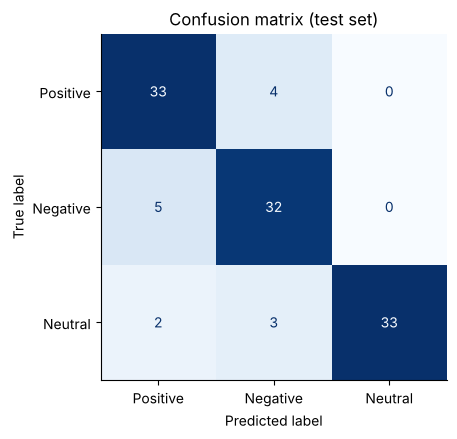

Positive class by hand:  precision = 33/(33+7) = 0.825,  recall = 33/(33+4) = 0.892


In [8]:
cm = confusion_matrix(y_test, y_pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (test set)")
plt.show()

# Verify the formulas by hand for one class
tp = cm[0, 0]; fp = cm[:, 0].sum() - tp; fn = cm[0, :].sum() - tp
print(f"Positive class by hand:  precision = {tp}/({tp}+{fp}) = {tp/(tp+fp):.3f},  recall = {tp}/({tp}+{fn}) = {tp/(tp+fn):.3f}")

## 7. Overfitting check

**Overfitting** = the model memorises the training data and does badly on new data.
Compare the training score with the test score: a very large gap is a warning sign.

In [9]:
train_acc = accuracy_score(y_train, model.predict(X_train_vec))
print(f"Training accuracy: {train_acc*100:.1f} %")
print(f"Test accuracy    : {accuracy*100:.1f} %")
print(f"Gap              : {(train_acc-accuracy)*100:.1f} percentage points")

Training accuracy: 100.0 %
Test accuracy    : 87.5 %
Gap              : 12.5 percentage points


The training score is higher than the test score, which is normal. The gap is the reason we always report the **test** score.
With a small dataset the gap can be large, which is one of the limitations of this project.

## 8. Cross-validation

One 80/20 split can be lucky or unlucky, especially with a small dataset.
**5-fold cross-validation** repeats training/testing 5 times with different splits and averages the result.

Accuracy of each fold: [90.2 86.6 87.4 80.2 80.2]
Mean: 84.9 %   (+/- 4.0)


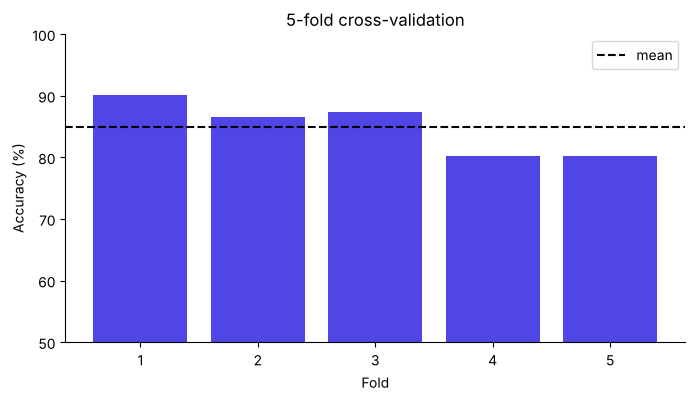

In [10]:
pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                     LogisticRegression(C=4.0, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(pipe, df["clean"], df["label"], cv=cv, scoring="accuracy")

print("Accuracy of each fold:", (scores * 100).round(1))
print(f"Mean: {scores.mean()*100:.1f} %   (+/- {scores.std()*100:.1f})")

plt.bar(range(1, 6), scores * 100, color="#4f46e5")
plt.axhline(scores.mean() * 100, color="black", ls="--", label="mean")
plt.ylim(50, 100); plt.xlabel("Fold"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.title("5-fold cross-validation")
plt.show()

## 9. Comparing different algorithms

Why Logistic Regression? Let us compare it with other common algorithms using the same cross-validation.

In [11]:
candidates = {
    "Naive Bayes":         MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(C=4.0, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Linear SVM":          LinearSVC(C=1.0, random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}
results = []
for name, clf in candidates.items():
    p_ = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), clf)
    s = cross_val_score(p_, df["clean"], df["label"], cv=cv, scoring="accuracy")
    results.append({"Model": name, "CV accuracy (%)": round(s.mean() * 100, 1), "Std": round(s.std() * 100, 1)})
results = pd.DataFrame(results).sort_values("CV accuracy (%)", ascending=False).reset_index(drop=True)
results

,Model,CV accuracy (%),Std
0,Naive Bayes,84.9,2.7
1,Logistic Regression,84.9,4.0
2,Linear SVM,84.7,3.8
3,Random Forest,79.5,2.6


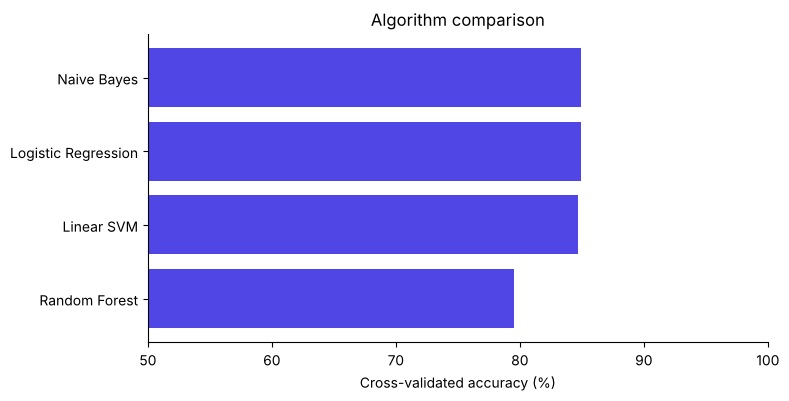

In [12]:
plt.barh(results["Model"][::-1], results["CV accuracy (%)"][::-1], color="#4f46e5")
plt.xlim(50, 100); plt.xlabel("Cross-validated accuracy (%)"); plt.title("Algorithm comparison")
plt.show()

We chose **Logistic Regression** because it is accurate on text, fast, gives **real probabilities** (needed for the confidence score)
and its weights are easy to explain. Linear SVM is similar but does not give probabilities directly.
(With such a small dataset, differences of 1-3 points between models are not significant.)

## 10. Effect of the regularisation setting `C`

`C` controls how strongly the model is prevented from overfitting. Small C = simpler model, large C = fits training data more closely.

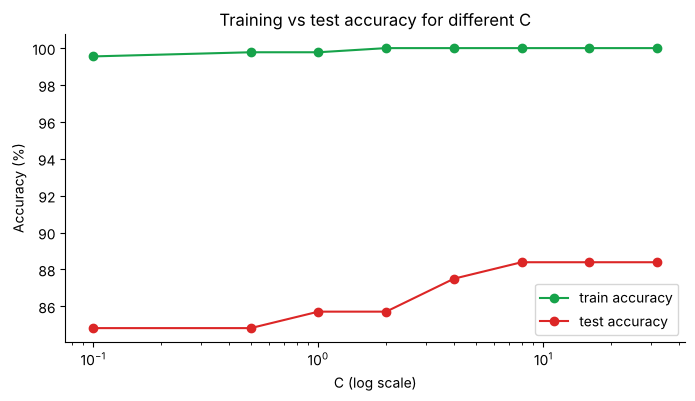

,C,train,test
0,0.1,99.6,84.8
1,0.5,99.8,84.8
2,1.0,99.8,85.7
3,2.0,100.0,85.7
4,4.0,100.0,87.5
5,8.0,100.0,88.4
6,16.0,100.0,88.4
7,32.0,100.0,88.4


In [13]:
rows = []
for C in [0.1, 0.5, 1, 2, 4, 8, 16, 32]:
    m = LogisticRegression(C=C, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE).fit(X_train_vec, y_train)
    rows.append({"C": C, "train": accuracy_score(y_train, m.predict(X_train_vec)) * 100,
                 "test": accuracy_score(y_test, m.predict(X_test_vec)) * 100})
c_df = pd.DataFrame(rows)
plt.plot(c_df["C"], c_df["train"], "o-", label="train accuracy", color="#16a34a")
plt.plot(c_df["C"], c_df["test"], "o-", label="test accuracy", color="#dc2626")
plt.xscale("log"); plt.xlabel("C (log scale)"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.title("Training vs test accuracy for different C")
plt.show()
c_df.round(1)

## 11. What did the model learn?

Because Logistic Regression is linear, we can read the weights directly: the words with the **largest positive weight** for a class
push the prediction towards that class.

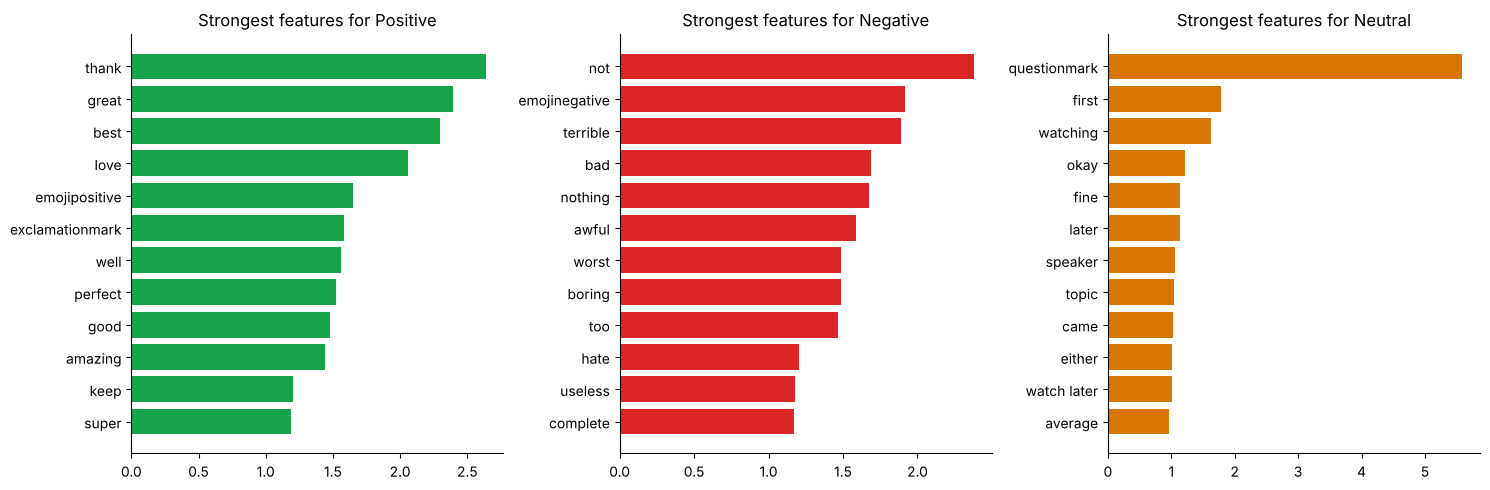

In [14]:
feature_names = np.array(vectorizer.get_feature_names_out())
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, label in zip(axes, LABELS):
    idx = list(model.classes_).index(label)
    weights = model.coef_[idx]
    top = np.argsort(weights)[-12:]
    ax.barh(feature_names[top], weights[top], color=COLORS[label])
    ax.set_title(f"Strongest features for {label}")
plt.tight_layout(); plt.show()

## 12. Where does the model make mistakes?

Looking at wrong predictions is the best way to understand a model's limits.

In [15]:
errors = pd.DataFrame({"comment": df.loc[X_test.index, "text"], "actual": y_test, "predicted": y_pred})
errors = errors[errors["actual"] != errors["predicted"]]
print(f"{len(errors)} wrong predictions out of {len(y_test)}\n")
errors.head(12)

14 wrong predictions out of 112



,comment,actual,predicted
91,"I appreciate how you didn't skip any steps, very beginner friendly",Positive,Negative
301,"Cool, but I already knew most of this",Neutral,Negative
303,The channel posts new videos every Friday,Neutral,Positive
182,"Poor explanation, I am more confused than before",Negative,Positive
311,It would be nice to have a transcript,Neutral,Positive
556,Hello from Delhi 🇮🇳,Neutral,Negative
336,The channel has about one million subscribers now,Neutral,Negative
228,The animations are ugly and distracting,Negative,Positive
145,Cringe from start to finish,Negative,Positive
48,"The humor in this is on point, I laughed so hard",Positive,Negative


Typical reasons: mixed feelings ("good content but too fast"), sarcasm, rare words never seen in training, very short comments like "ok".

## 13. Predict new comments (with confidence)

`predict_proba` gives the probability of each class. The confidence shown in the web app is the highest probability.

In [16]:
new_comments = [
    "I really enjoyed this video. The explanation was excellent!",
    "Waste of time, the audio is terrible",
    "What software is used at 3:45?",
    "Not bad at all, I learned a lot",
    "It was okay I guess",
    "Please make a video on neural networks",
]
vec = vectorizer.transform([clean_text(c) for c in new_comments])
proba = model.predict_proba(vec)

out = pd.DataFrame(proba, columns=model.classes_).round(3)
out.insert(0, "comment", new_comments)
out["prediction"] = model.classes_[proba.argmax(axis=1)]
out["confidence"] = (proba.max(axis=1) * 100).round(0).astype(int).astype(str) + " %"
out

,comment,Negative,Neutral,Positive,prediction,confidence
0,I really enjoyed this video. The explanation was excellent!,0.034,0.033,0.933,Positive,93 %
1,"Waste of time, the audio is terrible",0.898,0.066,0.036,Negative,90 %
2,What software is used at 3:45?,0.040,0.936,0.024,Neutral,94 %
3,"Not bad at all, I learned a lot",0.687,0.169,0.144,Negative,69 %
4,It was okay I guess,0.138,0.731,0.131,Neutral,73 %
5,Please make a video on neural networks,0.162,0.463,0.375,Neutral,46 %


### Try your own comment

In [17]:
my_comment = "This tutorial was amazing, thank you so much!"   # <- change this text and run again

v = vectorizer.transform([clean_text(my_comment)])
pr = model.predict_proba(v)[0]
print("Comment   :", my_comment)
print("Sentiment :", model.classes_[pr.argmax()])
print("Confidence:", f"{pr.max()*100:.0f} %")
for cls, pv in zip(model.classes_, pr):
    print(f"   {cls:<9} {'#' * int(pv * 40):<40} {pv*100:5.1f} %")

Comment   : This tutorial was amazing, thank you so much!
Sentiment : Positive
Confidence: 97 %
   Negative                                             1.6 %
   Neutral                                              1.5 %
   Positive  ######################################    96.9 %


## 14. Save the model

The web app loads these files with `joblib`. (Running `python ml/train.py` creates the same files.)

> **Warning:** running the next cell **overwrites** the model in `models/`. It is optional for the demonstration,
> so it is switched off by default. Set `SAVE_MODEL = True` to run it.

In [18]:
import joblib

SAVE_MODEL = False     # change to True to overwrite models/*.pkl

if SAVE_MODEL:
    models_dir = PROJECT_DIR / "models"
    models_dir.mkdir(exist_ok=True)
    joblib.dump(vectorizer, models_dir / "vectorizer.pkl")
    joblib.dump(model, models_dir / "sentiment_model.pkl")
    print("Saved to", models_dir)
else:
    print("SAVE_MODEL is False, nothing was saved. Use `python ml/train.py` to train and save the real model.")

SAVE_MODEL is False, nothing was saved. Use `python ml/train.py` to train and save the real model.


## 15. Summary

| Item | Value |
|---|---|
| Task | multi-class text classification (Positive / Negative / Neutral) |
| Features | TF-IDF with unigrams + bigrams |
| Model | Logistic Regression (`C=4`, balanced class weights) |
| Evaluation | held-out test set + 5-fold cross-validation |
| Metrics | accuracy, precision, recall, F1, confusion matrix |

**Limitations**
- Small, hand-labelled dataset, so real YouTube accuracy will be lower
- Sarcasm, slang and mixed-language comments are hard
- Bag-of-words ignores long-range context

**Future work:** larger dataset, lemmatization, hyper-parameter search, transformer models such as BERT.